# 1D-CNN training

Load the synthetic spectra produced by `01_datagen.ipynb`, run a Bayesian hyperparameter search over a 1D-CNN with MC Dropout, train the best configuration, and evaluate on the held-out test split.

## Setup

In [2]:
import os, sys
from pathlib import Path

IN_COLAB = "google.colab" in str(get_ipython())

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")

    REPO_ROOT = Path("/content/drive/MyDrive/spectral-windows-for-m-dwarf-host-stars")

    import subprocess

    subprocess.run(
        [
            "pip",
            "install",
            "-q",
            "numpy",
            "pandas",
            "pyarrow",
            "matplotlib",
            "tqdm",
            "tensorflow==2.20.0",
            "keras-tuner==1.4.7",
            "scikit-learn",
            "visualkeras",
            "pillow",
        ],
        check=True,
    )
else:
    REPO_ROOT = Path.cwd().parents[1]

sys.path.insert(0, str(REPO_ROOT))
print("REPO_ROOT:", REPO_ROOT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
REPO_ROOT: /content/drive/MyDrive/spectral-windows-for-m-dwarf-host-stars


In [3]:
import numpy as np
import pandas as pd

import src.datavis as datavis
from src.dataset import load_spectra_parquets, prepare_splits, make_tf_datasets
from src.models import HyperTuningBayCNN

## Experimental setup

In [4]:
DATA_DIR = os.path.join(REPO_ROOT, "data")
RESULTS_DIR = os.path.join(REPO_ROOT, "results")
os.makedirs(RESULTS_DIR, exist_ok=True)

OUTPUT_TARGETS = ("Teff_K", "logg_cgs", "FeH_dex")
BATCH_SIZE = 32

# Hyperparameter search budget
MAX_TRIALS = 20
SEARCH_EPOCHS = 2

# Final training
EPOCHS = 50
PATIENCE = 8

## Load data

In [6]:
df = load_spectra_parquets(DATA_DIR)
print("shape:", df.shape)
df.head()

shape: (5000, 8)


,Teff_K,logg_cgs,FeH_dex,Mass_Msun,Radius_Rsun,wavelength_A,flux,continuum
0,3129.031349,4.903465,-0.398154,0.317017,0.329086,"[8800.0, 8800.009765625, 8800.01953125, 8800.0...","[0.9995366334915161, 0.999535858631134, 0.9995...","[554887.0625, 554887.0, 554886.9375, 554886.87..."
1,3298.260177,4.950254,-0.062917,0.292977,0.299771,"[8800.0, 8800.009765625, 8800.01953125, 8800.0...","[0.9991995692253113, 0.9991980791091919, 0.999...","[698598.9375, 698598.6875, 698598.4375, 698598..."
2,3366.889872,4.939689,-0.076755,0.310197,0.312230,"[8800.0, 8800.009765625, 8800.01953125, 8800.0...","[0.9991275668144226, 0.9991258978843689, 0.999...","[747425.6875, 747425.375, 747425.0, 747424.687..."
3,3454.222712,4.928937,-0.050838,0.304602,0.313255,"[8800.0, 8800.009765625, 8800.01953125, 8800.0...","[0.9989616870880127, 0.9989596605300903, 0.998...","[818224.875, 818224.4375, 818224.0, 818223.562..."
4,3727.077236,4.755964,0.032868,0.477035,0.478402,"[8800.0, 8800.009765625, 8800.01953125, 8800.0...","[0.998212456703186, 0.9982085227966309, 0.9982...","[1052843.625, 1052842.75, 1052841.875, 1052841..."


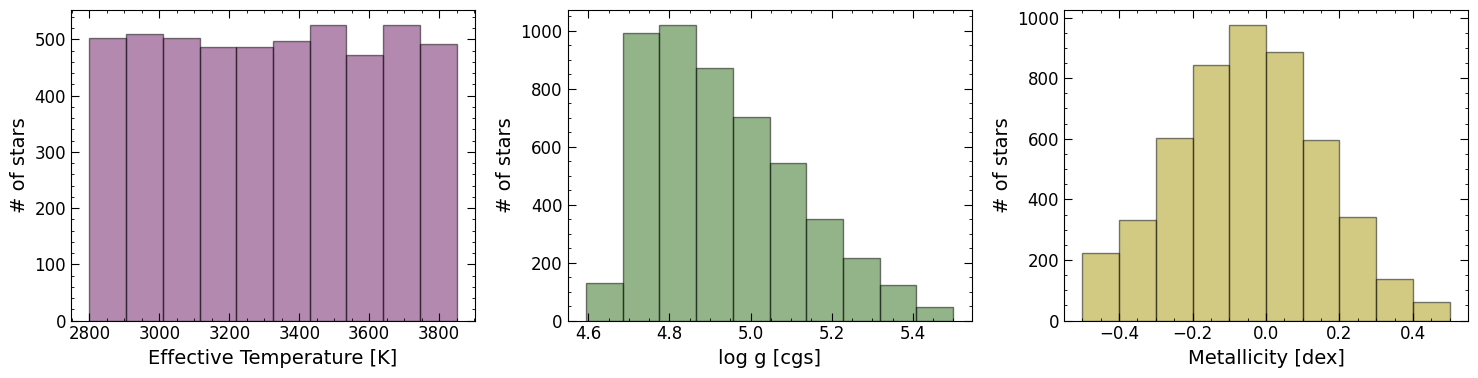

In [9]:
import matplotlib.pyplot as plt

labels = ["Effective Temperature [K]", "log g [cgs]", "Metallicity [dex]"]
colors = ["#691463", "#286914", "#A69608"]

fig, axes = plt.subplots(1, len(OUTPUT_TARGETS), figsize=(15, 4))
for ax, col, color, label in zip(axes, OUTPUT_TARGETS, colors, labels):
    ax.hist(df[col], bins=10, edgecolor="k", color=color, alpha=0.5)
    ax.set_xlabel(label)
    ax.set_ylabel("# of stars")

fig.tight_layout()

## Splits and tf.data pipelines

In [10]:
splits = prepare_splits(df, output_targets=OUTPUT_TARGETS)
train_dataset, validation_dataset, test_dataset = make_tf_datasets(
    splits, batch_size=BATCH_SIZE
)

input_shape = splits.X_train.shape[1:]
print("input_shape:", input_shape)
print(
    "train:",
    splits.X_train.shape,
    "  val:",
    splits.X_val.shape,
    "  test:",
    splits.X_test.shape,
)

input_shape: (3501, 1)
train: (4050, 3501, 1)   val: (450, 3501, 1)   test: (500, 3501, 1)


## Bayesian hyperparameter search

In [11]:
cnn_tuner = HyperTuningBayCNN(
    input_shape=input_shape,
    outputs_list=OUTPUT_TARGETS,
    tuner_directory=os.path.join(RESULTS_DIR, "hyperparam_search"),
    project_name="cnn_bay_tuning",
)

best_hps = cnn_tuner.search(
    train_dataset,
    validation_dataset,
    max_trials=MAX_TRIALS,
    search_epochs=SEARCH_EPOCHS,
)
best_hps.values

Reloading Tuner from /content/drive/MyDrive/spectral-windows-for-m-dwarf-host-stars/results/hyperparam_search/cnn_bay_tuning/tuner0.json


{'conv_blocks': 2,
 'filters_b0_a': 48,
 'kernel_b0_a_ks': 3,
 'filters_b0_b': 80,
 'kernel_b0_b_ks': 5,
 'dropout_rate_conv_b0': 0.0,
 'dense_layers': 3,
 'units_dense_0': 448,
 'dropout_rate_dense_0': 0.4,
 'learning_rate': 1.0422037472719066e-05,
 'filters_b1_a': 128,
 'kernel_b1_a_ks': 9,
 'filters_b1_b': 64,
 'kernel_b1_b_ks': 3,
 'dropout_rate_conv_b1': 0.2,
 'filters_b2_a': 32,
 'kernel_b2_a_ks': 3,
 'filters_b2_b': 80,
 'kernel_b2_b_ks': 7,
 'dropout_rate_conv_b2': 0.1,
 'units_dense_1': 448,
 'dropout_rate_dense_1': 0.30000000000000004,
 'units_dense_2': 320,
 'dropout_rate_dense_2': 0.0}

## Train the best model

In [12]:
best_model, history = cnn_tuner.fit_best_model(
    train_dataset,
    validation_dataset,
    epochs=EPOCHS,
    patience=PATIENCE,
)
cnn_tuner.summary()

Epoch 1/50
127/127 ━━━━━━━━━━━━━━━━━━━━ 36s 140ms/step - FeH_dex_loss: 0.8517 - Teff_K_loss: 0.3873 - logg_cgs_loss: 0.9503 - loss: 2.2092 - val_FeH_dex_loss: 0.9839 - val_Teff_K_loss: 1.0253 - val_logg_cgs_loss: 1.0407 - val_loss: 2.9850
Epoch 2/50
127/127 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - FeH_dex_loss: 0.6217 - Teff_K_loss: 0.1946 - logg_cgs_loss: 0.7822 - loss: 1.6169 - val_FeH_dex_loss: 0.9803 - val_Teff_K_loss: 1.0059 - val_logg_cgs_loss: 1.0448 - val_loss: 2.9588
Epoch 3/50
127/127 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - FeH_dex_loss: 0.4694 - Teff_K_loss: 0.1497 - logg_cgs_loss: 0.5755 - loss: 1.2126 - val_FeH_dex_loss: 0.9942 - val_Teff_K_loss: 0.9452 - val_logg_cgs_loss: 1.0314 - val_loss: 2.8707
Epoch 4/50
127/127 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - FeH_dex_loss: 0.3166 - Teff_K_loss: 0.1098 - logg_cgs_loss: 0.3942 - loss: 0.8384 - val_FeH_dex_loss: 1.0709 - val_Teff_K_loss: 0.7384 - val_logg_cgs_loss: 0.9978 - val_loss: 2.6710
Epoch 5/50
127/127 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step -

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 3501, 1)   │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 3501, 48)  │        192 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 3501, 80)  │     19,280 │ conv1d[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d       │ (None, 1750, 80)  │          0 │ conv1d_1[0][0]    │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 1750, 80)  │        320 │ max_pooling1d[0]… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_mc_dropout  │ (None, 1750, 80)  │          0 │ batch_normalizat… │
│ (SpatialMCDropout)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, 1750, 128) │     92,288 │ spatial_mc_dropo… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_3 (Conv1D)   │ (None, 1750, 64)  │     24,640 │ conv1d_2[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_1     │ (None, 875, 64)   │          0 │ conv1d_3[0][0]    │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 875, 64)   │        256 │ max_pooling1d_1[… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_mc_dropout… │ (None, 875, 64)   │          0 │ batch_normalizat… │
│ (SpatialMCDropout)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 56000)     │          0 │ spatial_mc_dropo… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 448)       │ 25,088,448 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mc_dropout          │ (None, 448)       │          0 │ dense[0][0]       │
│ (MCDropout)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 448)       │    201,152 │ mc_dropout[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mc_dropout_1        │ (None, 448)       │          0 │ dense_1[0][0]     │
│ (MCDropout)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 320)       │    143,680 │ mc_dropout_1[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mc_dropout_2        │ (None, 320)       │          0 │ dense_2[0][0]     │
│ (MCDropout)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ FeH_dex (Dense)     │ (None, 1)         │        321 │ mc_dropout_2[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Teff_K (Dense)      │ (None, 1)         │        321 │ mc_dropout_2[0][

 Total params: 76,713,082 (292.64 MB)

 Trainable params: 25,570,931 (97.55 MB)

 Non-trainable params: 288 (1.12 KB)

 Optimizer params: 51,141,863 (195.09 MB)

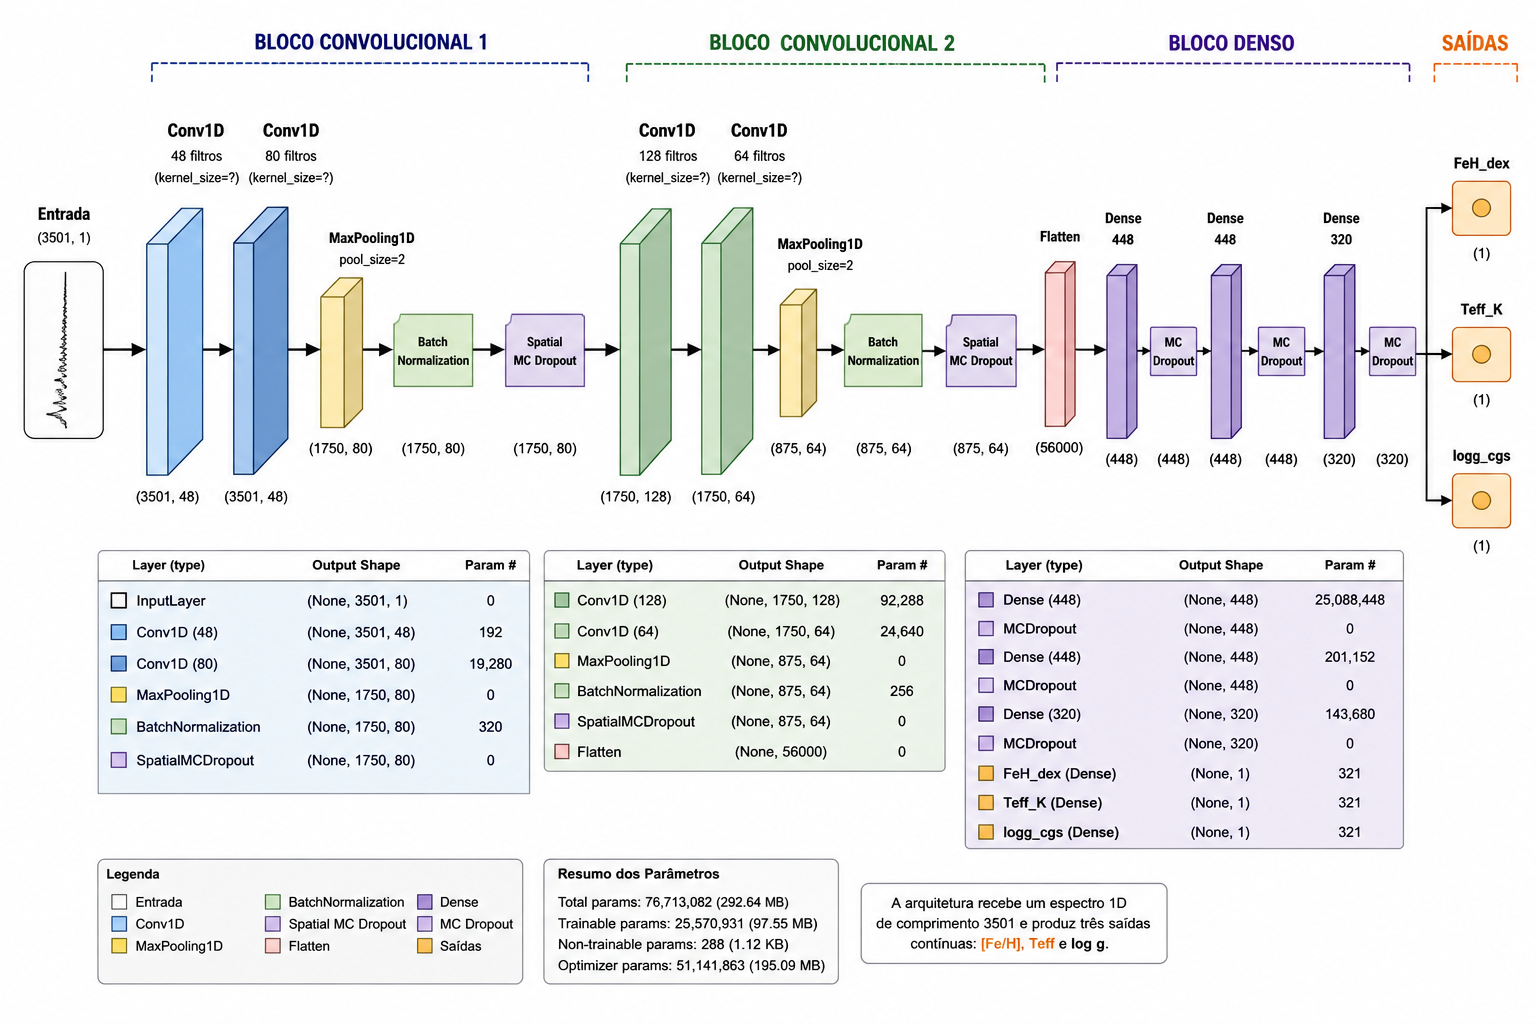

In [ ]:
from IPython.display import Image as IPImage

IPImage(str(REPO_ROOT / "figures" / "model-baseline.png"), width=900)

## Loss curves

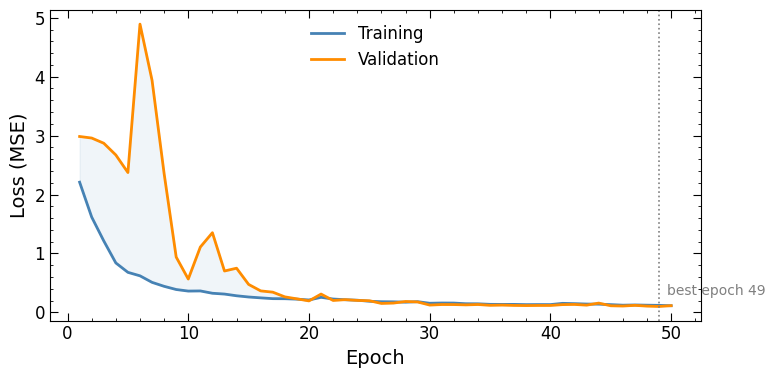

In [15]:
fig, ax = cnn_tuner.plot_losses(show=True)

## Evaluation on the test split

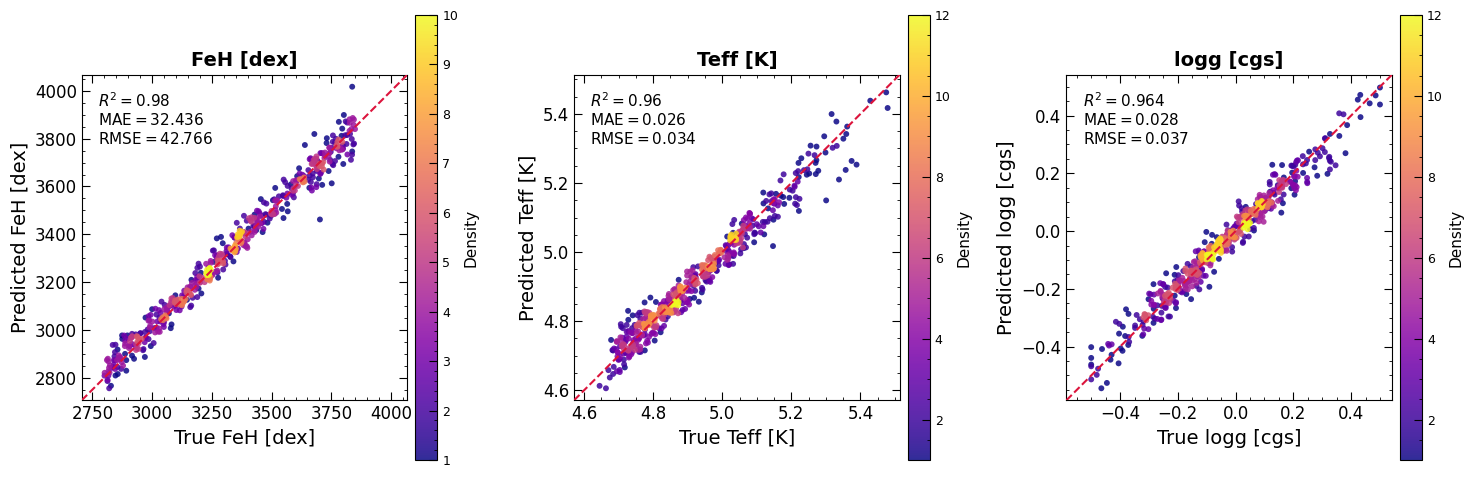

,R2,MAE,MSE,RMSE
FeH [dex],0.980,32.436,1828.913,42.766
Teff [K],0.960,0.026,0.001,0.034
logg [cgs],0.964,0.028,0.001,0.037


In [16]:
feature_names = ["FeH [dex]", "Teff [K]", "logg [cgs]"]
results, fig_axs = cnn_tuner.evaluate(
    test_dataset,
    feature_names=feature_names,
    y_scalers=splits.output_scalers,
    plot=True,
)
results

In [17]:
fig, axs = fig_axs
fig.savefig(REPO_ROOT / "figures" / "evaluation.png", dpi=150, bbox_inches="tight")

## Save the trained model

In [18]:
cnn_tuner.best_model.save(os.path.join(RESULTS_DIR, "model-baseline.keras"))